In [4]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
from scipy.interpolate import RegularGridInterpolator
import seaborn as sns
import matplotlib
from module_pp import *


In [35]:

## astronomical constants        
kb = 1.38065e-16 # boltzmann's constant
mh = 1.673558e-24 # mass of hydrogen atom in grams
sigma = 5.6704e-5 # stefan-Boltzmann constant

G=6.67408e-8 # Gravitational constant

earth_mass_to_g = 5.972e27
earth_radius_to_cm = 6.371e8
Mearth = earth_mass_to_g*1e-3 # kg
Rearth = earth_radius_to_cm*1e-2 # m
rho_earth_cgs = 5.51 # density of Earth
year_to_sec = 31557600. # number of seconds in a year
gyr_to_sec = 1e9*year_to_sec
day_to_sec = 86400. # number of secconds in a day

Tsun = 5778. #K
Rsun = 6.9551e8 # m
Msun = 1.9885e30 #kg
Lsun = 3.828e26 #W
Fxuv_earth = 0.67e-3 #W/m^2
Fxuv_earth_cgs = 4.666
au_to_cm = 1.496e13
AU = au_to_cm*1e-2
Period_Earth = 365.25 #days

#My units in SI
me = 5.972e24
re = 6.371e6

Ggrav=6.67408e-11
sigmasb=5.670374419e-8
gyr=gyr_to_sec
Rmol=8.31446261815324
Nav=6.02214076e23
Teq_e=5772.0*np.sqrt(1.362e9/(4.0*1.5e11))


def massloss_energy_limited(
    fxuv   :float,
    mstar  :float,
    mass   :float,
    radius :float,
    sep    :float,
    eff  :float = 1.0,
    beta :float = 1.0,
    **kwargs
    ) -> float:
    """
    Returns the mass loss rate from a planet using the
    energy-limited model.
    Required parameters must be defined in the state,
    optional parameters can be provided through model keywords.

    Parameters
    ----------
    fxuv    : float, XUV flux of the star at planet orbit
    mstar   : float, Host star mass 
    mass    : float, planet mass 
    radius  : float, planet radius 
    sep     : float, orbital separation of the planet
    eff  : float|callable (optional),
            evaporation efficiency.
    beta    : float, Rxuv/Rpl
    Returns
    -------
    mloss  : float, mass loss rate in kg/s
    """
    # lxuv   = (lx + leuv) * 1e-7
    # fxuv   = physics.get_flux(lum=lx+leuv, dist_au=sep)
    # fxuv  *= physics.units.erg.to('J') / physics.units.cm.to('m')**2
    # mstar  = mstar  * physics.constants.M_sun.value
    # mass   = mass   * physics.constants.M_earth.value
    # radius = radius * physics.constants.R_earth.value
    # sep    = sep    * physics.constants.au.value
    # fxuv   = lxuv / (4.0*np.pi*sep**2)
    # kwargs.update(lx=lx, leuv=leuv, mstar=mstar, mass=mass, radius=radius, sep=sep/physics.constants.au.value)
    # eff  = el_eff(**kwargs)  if callable(el_eff)  else el_eff
    # rxuv = beta*radius
    # grav = Ggrav*mass/(radius**2)
    # vesc = np.sqrt(2*grav*radius)
    # eff = 0.1*(vesc/15e3)**(-2)
    grav_const = Ggrav
    xi = (sep/radius)*(mass/mstar/3)**(1/3)
    ktide = 1 - 3/(2*xi) + 1/(2*(xi)**3) # Correction for the Roche lobe
    mloss = (beta**2)*eff*np.pi*fxuv*(radius**3)/(grav_const*ktide*mass)
    return mloss


In [36]:
file = "windae_nobolo_static_102325.dat"
file = "windae_nobolo_static_110325.dat"

df = pd.read_csv(file,sep="\t",header=27)

# Keys: 'Mp', 'Rp', 'grav', 'Teq', 'a', 'Fxuv', 'mstar', 'lstar', 'Mdot',
#       'MdotOW17', 'ramp_to', 'run_wind', 'rochelim'

df["MdotEL"] = massloss_energy_limited(df["Fxuv"]*Fxuv_earth_cgs,
                                       df["mstar"]*Msun,
                                       df["Mp"]*Mearth,
                                       df["Rp"]*Rearth,
                                       df["a"]*AU,)

df["MdotOW"] = mdot_ow17(df["Fxuv"]*Fxuv_earth_cgs,
                                       df["mstar"]*Msun,
                                       df["Mp"]*Mearth,
                                       df["Rp"]*Rearth,
                                       df["a"]*AU,)

df["H"] = (8.314*df["Teq"])/(18e-3*df["grav"])
df["Lambda"] = df["Rp"]*Rearth / df["H"]
df_filter = df[df["ramp_to"]+df["run_wind"]+df["rochelim"] == 0]

x = np.logspace(1,8)

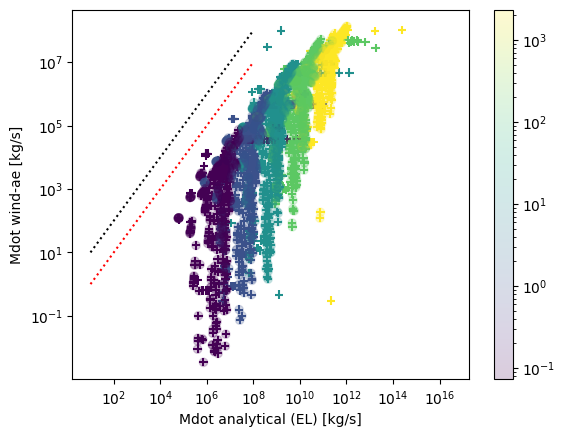

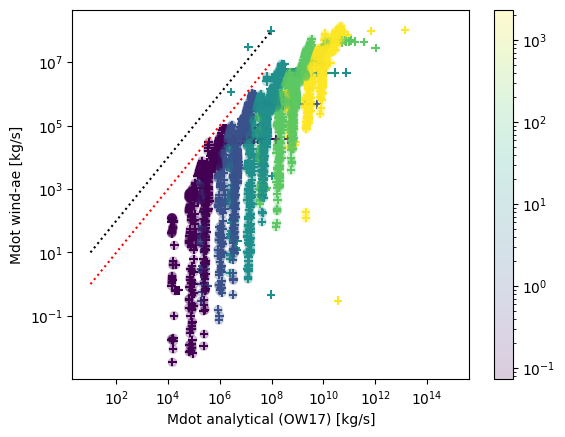

In [57]:
# Master plot 1: Mdot vs MdotEL.
# We see that Mdot can go up to 10 times the 100% efficiency,
# but otherwise most of the time efficiency <1
plt.scatter(df["MdotEL"],df["Mdot"],c=df["Fxuv"],alpha=1,marker='+',
norm=matplotlib.colors.LogNorm())
plt.scatter(df_filter["MdotEL"],df_filter["Mdot"],alpha=0.2,c=df_filter["Fxuv"],
norm=matplotlib.colors.LogNorm())
plt.plot(x,x,c='k',ls=':',label="100% efficiency")
plt.plot(x,0.1*x,c='r',ls=':',label="10% efficiency")
plt.colorbar();plt.xscale('log');plt.yscale('log')
plt.ylabel('Mdot wind-ae [kg/s]')
plt.xlabel('Mdot analytical (EL) [kg/s]')
plt.show()
# Same but with OW17
plt.scatter(df["MdotOW"],df["Mdot"],c=df["Fxuv"],alpha=1,marker='+',
norm=matplotlib.colors.LogNorm())
plt.scatter(df_filter["MdotOW"],df_filter["Mdot"],alpha=0.2,c=df_filter["Fxuv"],
norm=matplotlib.colors.LogNorm())
plt.plot(x,x,c='k',ls=':',label="100% efficiency")
plt.plot(x,0.1*x,c='r',ls=':',label="10% efficiency")
plt.colorbar();plt.xscale('log');plt.yscale('log')
plt.ylabel('Mdot wind-ae [kg/s]')
plt.xlabel('Mdot analytical (OW17) [kg/s]')
plt.show()


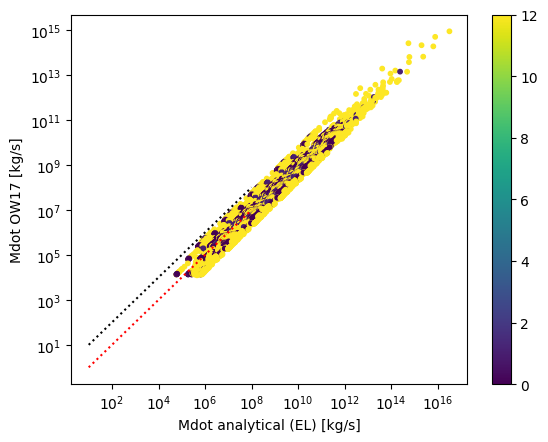

In [38]:
# check the 1:1 correspondence between MdotEL and MdotOW
# MdotEL assumes 100% efficiency, so Mdot should be smaller than MdotEL
plt.scatter(df["MdotEL"],df["MdotOW"],c=df["ramp_to"]+df["run_wind"]+df["rochelim"],s=10)
plt.plot(x,x,c='k',ls=':',label="100% efficiency")
plt.plot(x,0.1*x,c='r',ls=':',label="10% efficiency")
plt.colorbar();plt.xscale('log');plt.yscale('log')
plt.ylabel('Mdot OW17 [kg/s]')
plt.xlabel('Mdot analytical (EL) [kg/s]')
plt.show()


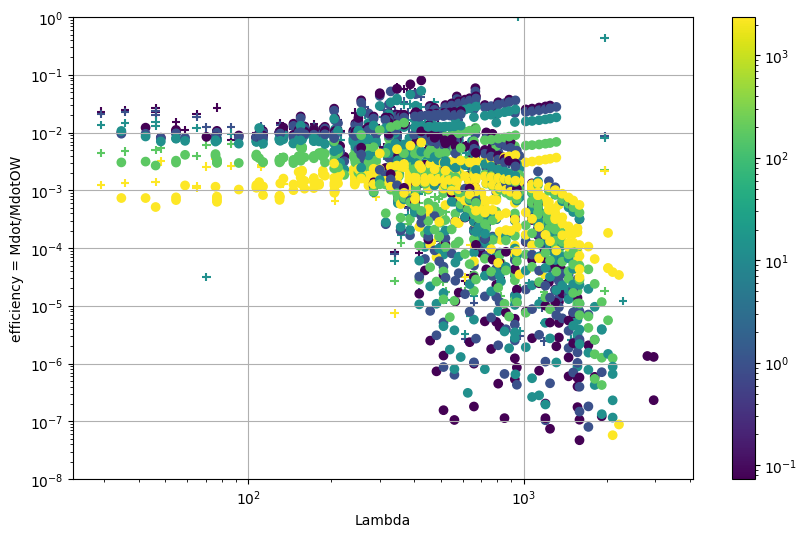

In [ ]:
# -----------------------------------------------------------

# Master plot 2: efficiency = Mdot/MdotEL as a fct of Lambda.
# for low values of Lambda (<300) there is a linear trend, and then 
# something more over the place, but with some trend in Teq
# plt.scatter(df["MdotEL"],df["Mdot"]/df["MdotEL"],c=df["ramp_to"]+df["run_wind"]+df["rochelim"])
plt.figure(figsize=(10, 6))
color_key = "Fxuv"
plt.scatter(df["Lambda"],df["Mdot"]/df["MdotOW"],c=df[color_key],marker='+',
norm=matplotlib.colors.LogNorm())
plt.scatter(df_filter["Lambda"],df_filter["Mdot"]/df_filter["MdotOW"],c=df_filter[color_key],
norm=matplotlib.colors.LogNorm())
plt.colorbar();plt.xscale('log');plt.yscale('log')
plt.ylabel('efficiency = Mdot/MdotOW')
plt.xlabel('Lambda')
plt.ylim(1e-8,1)
plt.grid()
plt.show()


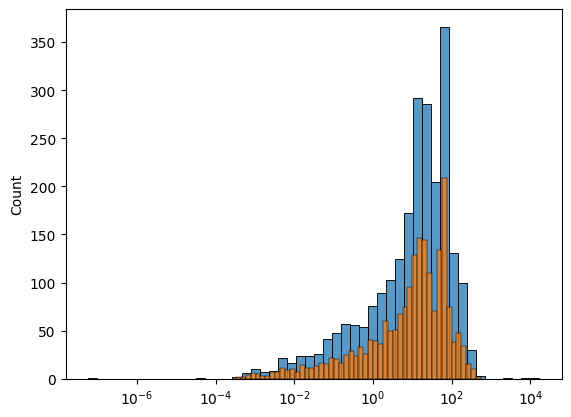

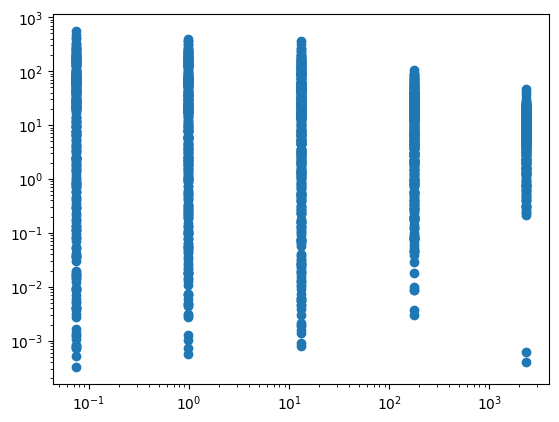

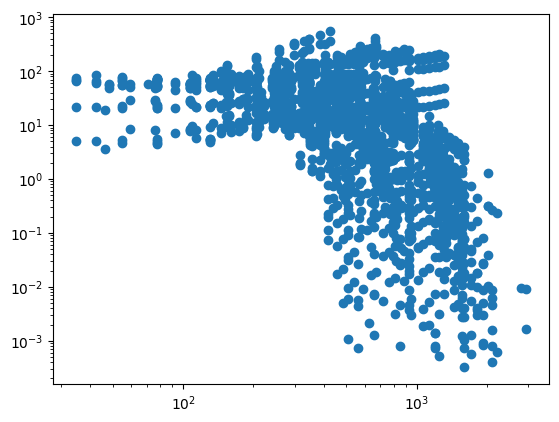

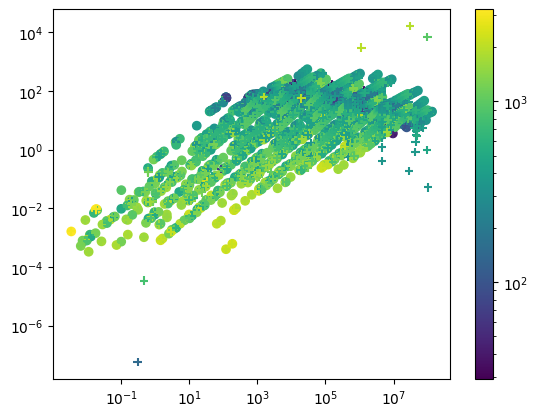

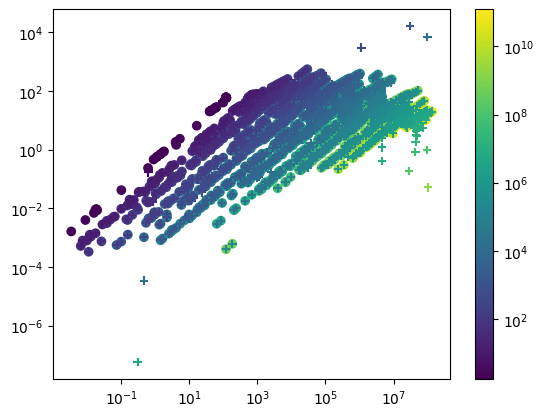

In [11]:

# -----------------------------------------------------------

# check the histogram of eff=Mdot/MdotEL ratios
sns.histplot(df["Mdot"]/df["MdotOW"],bins=50,log_scale=(True,False))
sns.histplot(df_filter["Mdot"]/df_filter["MdotOW"],bins=50,log_scale=(True,False));plt.show()


plt.scatter(df_filter["Fxuv"],df_filter["Mdot"]/df_filter["MdotOW"]);plt.xscale('log');plt.yscale("log");plt.show()

plt.scatter(df_filter["Lambda"],df_filter["Mdot"]/df_filter["MdotOW"]);plt.xscale('log');plt.yscale("log");plt.show()

#
plt.scatter(df_filter["Mdot"],df_filter["Mdot"]/df_filter["MdotOW"],c=df_filter["Lambda"],
norm=matplotlib.colors.LogNorm())
plt.scatter(df["Mdot"],df["Mdot"]/df["MdotOW"],c=df["Lambda"],marker="+",norm=matplotlib.colors.LogNorm())
plt.colorbar()
plt.xscale('log');plt.yscale("log");plt.show()

plt.scatter(df_filter["Mdot"],df_filter["Mdot"]/df_filter["MdotOW"],c=df_filter["MdotOW"],
norm=matplotlib.colors.LogNorm())
plt.scatter(df["Mdot"],df["Mdot"]/df["MdotOW"],c=df["MdotOW"],marker="+",norm=matplotlib.colors.LogNorm())
plt.colorbar()
plt.xscale('log');plt.yscale("log");plt.show()



In [12]:
df_filter.keys()

Index(['Mp', 'Rp', 'grav', 'Teq', 'a', 'Fxuv', 'mstar', 'lstar', 'Mdot',
       'MdotOW17', 'ramp_to', 'run_wind', 'rochelim', 'MdotEL', 'MdotOW', 'H',
       'Lambda'],
      dtype='object')

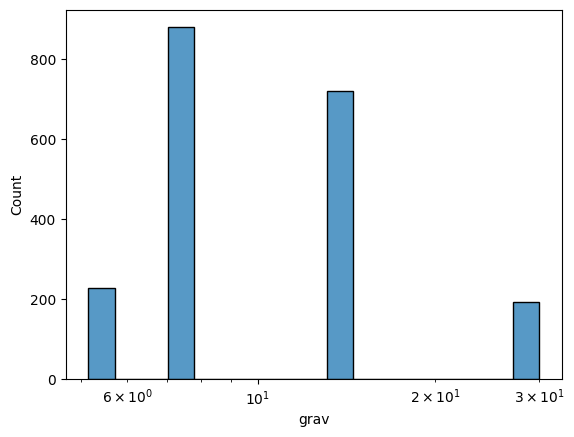

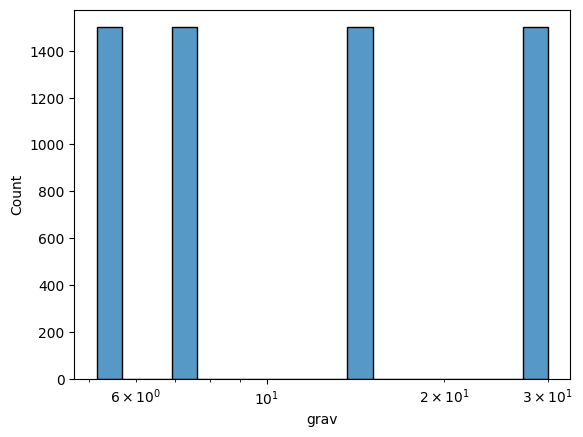

In [80]:
key_here = 'grav'
# df_filter[key_here].hist(bins=50)
sns.histplot(df_filter[key_here],log_scale=(True,False))
plt.show()
# df[key_here].hist(bins=50)
sns.histplot(df[key_here],log_scale=(True,False))
plt.show()

(0.2, 4.0)

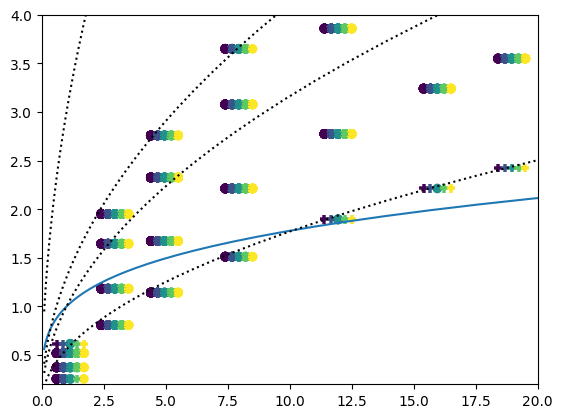

In [79]:
mass_arr=np.logspace(-1,1.5,50)
plt.scatter(df_filter['Mp']+df_filter['Teq']/1000,df_filter['Rp'],c=df_filter['Teq'])
plt.scatter(df['Mp']+df['Teq']/1000,df['Rp'],c=df['Teq'],marker='+')
plt.plot(mass_arr,mass_arr**0.25)

plt.plot(mass_arr,mass_arr**0.5*0.56,ls=":",c="k")
plt.plot(mass_arr,mass_arr**0.5,ls=":",c="k")
plt.plot(mass_arr,mass_arr**0.5*1.3,ls=":",c="k")
plt.plot(mass_arr,mass_arr**0.5*3,ls=":",c="k")

# plt.xscale('log')
plt.xlim(0,20)
plt.ylim(0.2,4)